In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready to use!')

c:\Users\ak60492\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model is ready to use!


In [2]:
# STEP-1: Define the state
from typing import TypedDict, Annotated
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('Graph state is ready..')

Graph state is ready..


In [ ]:
# STEP-2: Define the nodes
def assistant(state: AgentState) -> dict:
    """One graph node: call the model using current messages"""
    response = model.invoke(state['messages'])
    return {"messages": [response]}

print('Graph Nodes are ready')

Graph Nodes are ready


Graph is ready...


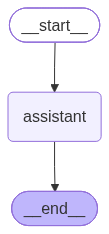

In [4]:
# STEP-3: Add edges and build the graph
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant", assistant)

# Add edges
graph_builder.add_edge(START, "assistant")
graph_builder.add_edge("assistant", END)

graph = graph_builder.compile()
print('Graph is ready...')
graph

In [5]:
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "Which is the capital of India?"}
    ]
})
response

{'messages': [HumanMessage(content='Which is the capital of India?', additional_kwargs={}, response_metadata={}, id='1120a24d-f12e-4e4e-85e2-7daa7ffa63f5'),
  AIMessage(content='The capital of India is **New\u202fDelhi**.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-30T10:17:28.322792224Z', 'done': True, 'done_reason': 'stop', 'total_duration': 262103101, 'load_duration': None, 'prompt_eval_count': 74, 'prompt_eval_duration': None, 'eval_count': 46, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a18c50-81c9-75e2-9175-83d88efadbe7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 74, 'output_tokens': 46, 'total_tokens': 120})]}